In [98]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from utils import *

In [220]:
with open("/Users/eochoa/Downloads/Machine Learning/label_name.json") as f:
    label_name = json.load(f)
    
with open("/Users/eochoa/Downloads/Machine Learning/mpid_label.json") as f:
    mpid_label = json.load(f)
    
with open("/Users/eochoa/Downloads/Machine Learning/mpid_type.json") as f:
    mpid_type = json.load(f)

label_name = pd.DataFrame({'mpid':np.int64(list(mpid_type.keys())), 'polymer':mpid_type.values()})

label_name.columns = ['mpid', 'pol_short_names']

dict_polymers = pd.read_csv('dict_polymers.csv')
del dict_polymers['Unnamed: 0']

polymer_list_flopp = np.array(dict_polymers['polymer'])

dict_polymers_2 = pd.concat([pd.DataFrame({'pol_short_names':['HDPE', 'LDPE', 'LLDPE', 'PTFE', 'POM', 'PVDF', 'PCL', 'PPO', 'PAN', 'EVOH', 'PVOH', 'CPE'],
'polymer':['High Density Polyethylene', 
'Low Density Polyethylene', 
'Linear Low Density Polyethylene',
'Polytetrafluoroethylene', 
'Polyoxymethylene', 
'Polyvinylidene Fluoride', 
'Polycaprolactone', 
'Polyphenylene Oxide',
'Polyacrylonitrile', 
'Ethylene Vinyl Alcohol', 
'Polyvinyl Alcohol',
'Chlorinated Polyethylene'
]}), dict_polymers])

label_name = label_name.merge(dict_polymers_2, left_on='pol_short_names', right_on='pol_short_names', how='left')
label_name['in_flopp'] = [p in np.array(dict_polymers['pol_short_names']) for p in label_name['pol_short_names']]

In [221]:
path = '/Users/eochoa/Downloads/Machine Learning/'
files = os.listdir(path)
files.remove('label_name.json')
files.remove('mpid_type.json')
files.remove('mpid_label.json')
files

['mpc3_pivot.csv',
 'mpb1_pivot.csv',
 'mpc2_pivot.csv',
 'mpc4_pivot.csv',
 'mpc1_pivot.csv',
 'mpb3_pivot.csv',
 'mpb2_pivot.csv']

In [136]:
spectra_list = []#[pd.read_csv(path + f) for f in files]

for f in files[1:]:
    spectra_list_df = pd.read_csv(path + f)
    spectra_data_long = spectra_list_df.melt(id_vars=['name', 'mpid'])#
    spectra_data_long.iloc[:,2:] = spectra_data_long.iloc[:,2:].astype('float32')
    spectra_data_long.columns = ['file_name','mpid','wavelength','intensity']
    spectra_data_long['file_name'] = [f + str(fn) for fn in spectra_data_long['file_name']]
    spectra_data_long = spectra_data_long.merge(label_name)
    spectra_data_long = spectra_data_long.loc[:, ['file_name','wavelength','intensity','polymer']]
    spectra_data_long_int = interpol_spect(spectra_data_long, min_wl=674.9918, max_wl=3999.809,n=1725)
    spectra_data_int = spectra_data_long_int.pivot(
        index=['file_name','polymer'], 
        columns='wavelength', 
        values='intensity').reset_index()
    spectra_list.append(spectra_data_int)

In [222]:
spectra_df = pd.concat(spectra_list)
spectra_df.iloc[:,514] = (spectra_df.iloc[:,513] + spectra_df.iloc[:,515]) / 2
spectra_df.iloc[:,513] = (spectra_df.iloc[:,512] + spectra_df.iloc[:,515]) / 2
spectra_df.iloc[:,514] = (spectra_df.iloc[:,513] + spectra_df.iloc[:,515]) / 2
spectra_df = spectra_df.reset_index(drop=True)
#spectra_df = spectra_df.query('polymer in @polymer_list_flopp')
spectra_np = spectra_df.iloc[:,2:].to_numpy()
spectra_np_norm = ((spectra_np - spectra_np.mean(1)[:,None])/spectra_np.std(1)[:,None])

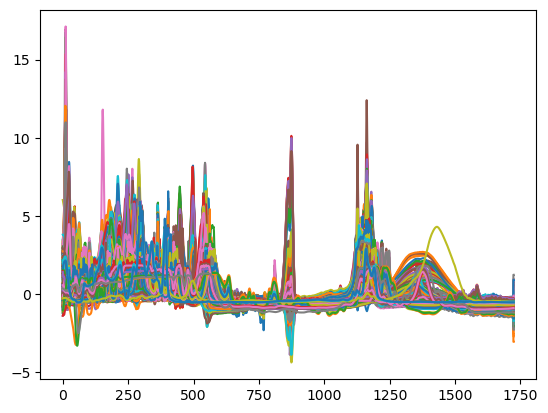

In [219]:
_ = plt.plot(spectra_np_norm.T)

In [224]:
spectra_df.to_csv('processed_data/mpb_mpc_data.csv')